In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, cross_val_score, KFold)
from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (r2_score, mean_squared_error)

<table>
  <tr>
    <th>libreria</th>
    <th>modulo</th>
    <th>clase</th>
    <th>funcion</th>
    <th>--USO--</th>
  </tr>
  <tr>
    <td>pandas</td>
    <td></td>
    <td></td>
    <td></td>
    <td>leer datos csv</td>
  </tr>
    <tr>
    <td>numpy</td>
    <td></td>
    <td></td>
    <td></td>
    <td>calculos numericos</td>
  </tr>
    <tr>
    <td>matplotlib</td>
    <td>pyplot</td>
    <td></td>
    <td></td>
    <td>graficos de todo tipo</td>
  </tr>
    <tr>
    <td>sklearn</td>
    <td>model_selection</td>
    <td></td>
    <td>train_test_split</td>
    <td>dividir datos en dos grupos</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>model_selection</td>
    <td></td>
    <td>cross_val_score</td>
    <td>evalua el modelo mediante validacion cruzada</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>model_selection</td>
    <td>kfold</td>
    <td></td>
    <td>define como se dividen los daros en pliegues</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>preprocessing</td>
    <td>PolynomialFeatures</td>
    <td></td>
    <td>crea potencias de la variable</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>preprocessing</td>
    <td>StandardScaler</td>
    <td></td>
    <td>estandariza los valores</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>linear_model</td>
    <td>LinearRegression</td>
    <td></td>
    <td>datos que forman una recta</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>metrics</td>
    <td></td>
    <td>r2_score</td>
    <td>0 - 1: que tanto sirve el modelo</td>
  </tr>
  <tr>
    <td>sklearn</td>
    <td>metrics</td>
    <td></td>
    <td>mean_square_error</td>
    <td>error cuadrado promedo del modelo</td>
  </tr>
</table>

In [30]:
df = pd.read_csv('./mpg.csv')

print('dimension:', df.shape)
display(df.head())

dimension: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [31]:
print(df.info())
print('-'*100)
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB
None
----------------------------------------------------------------------------------------------------
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [32]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


***Son 398 autos con 9 columnas, hay 6 datos faltantes en df['horsepower'], y entre "mpg" y "horsepower" la diferencia son los datos incompletos que tine horspower***

***PASO 3***<BR>_CORRELACIONES CON MPG_

In [33]:
correlaciones = df.select_dtypes(include="number").corr()["mpg"].sort_values()
print(correlaciones)

weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
mpg             1.000000
Name: mpg, dtype: float64


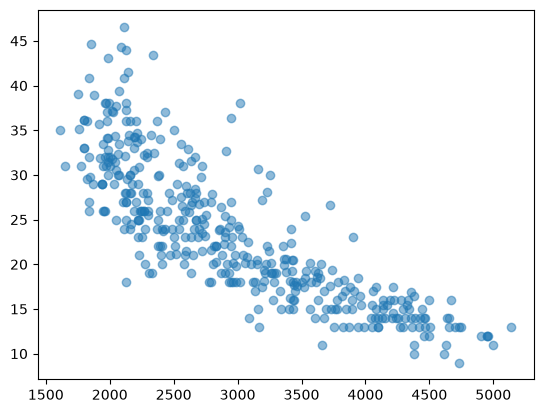

In [34]:
x = df['weight']
y = df['mpg']
plt.scatter(x, y, alpha=0.5)

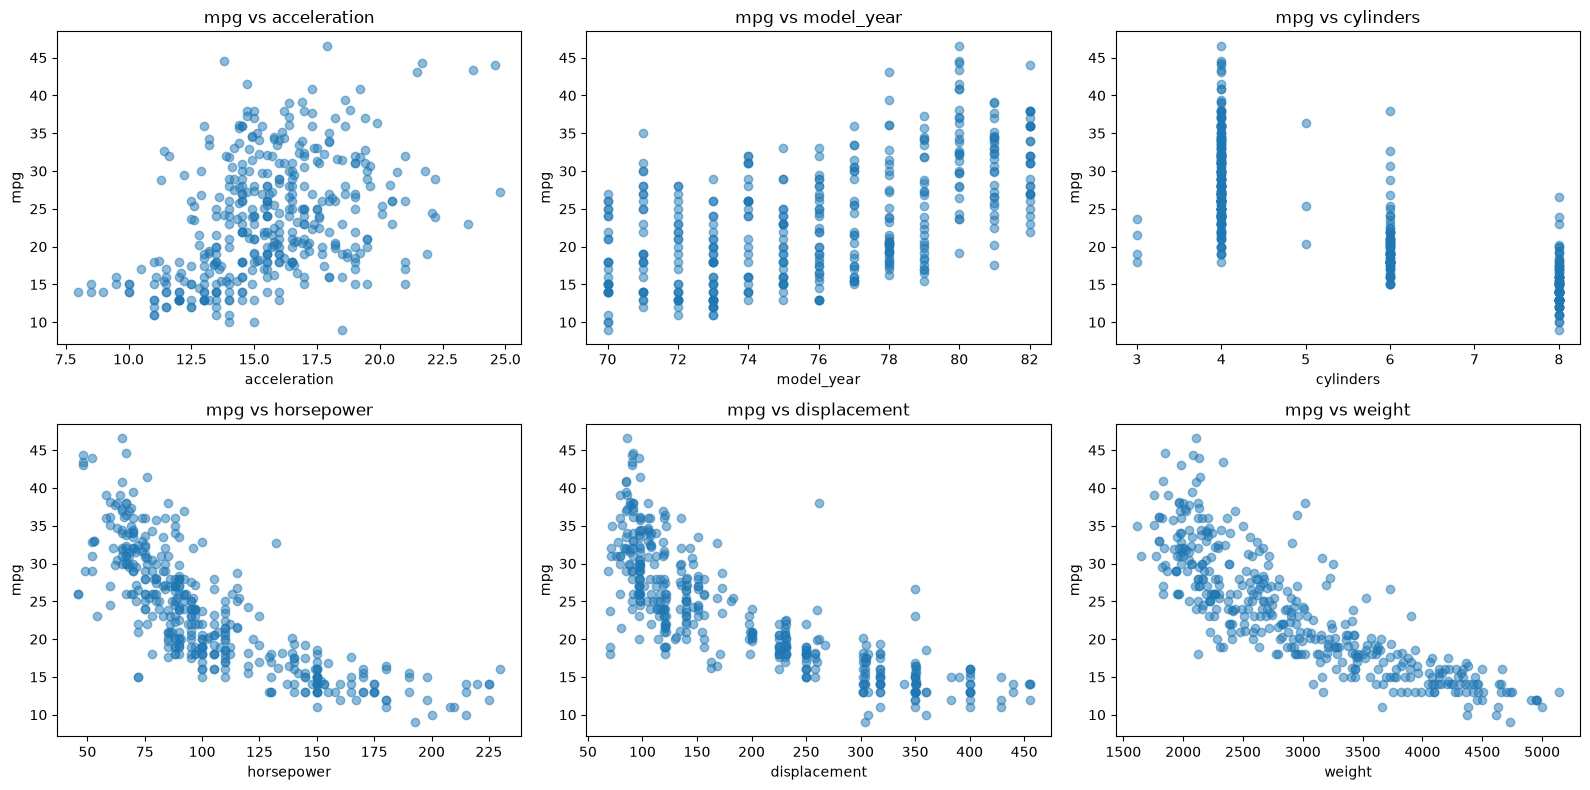

In [35]:
features = ['acceleration','model_year','cylinders', 'horsepower','displacement', 'weight']

plt.figure(figsize=(16, 8))
for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    plt.scatter(df[col], df['mpg'], alpha=0.5)
    plt.title(f'mpg vs {col}')
    plt.xlabel(col)
    plt.ylabel('mpg')

plt.tight_layout()
plt.show()

la variable con la relacion mas fuerte es weight. El sigo se anula porque se mide en abs(). El sgino de las demas correlaciones si influye, significa que a a mayor cantidad negativa, peor rendimiento en mpg y vicceversa en cantidades positivas. La regresion polinomica funciona bien curvandose, por lo tanto elevar a potencias ayuda a tener mayor control de la funcion.

***PASO 4***<BR>_LIMPIAR LOS DATOS_

In [36]:
datos = df[["horsepower", "mpg"]]
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB


In [37]:
datos = datos.dropna()

In [38]:
datos.info()

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         392 non-null    float64
dtypes: float64(2)
memory usage: 9.2 KB


representa el 1.51%, como se ve no es un porcentaje grande por lo que no afecta en gran medida que los eliminemos, e imputaria los datos cuando faltan mucho o sean pocos datos.

***PASO 5***<BR>_VISUALIZAR LA RELACION_

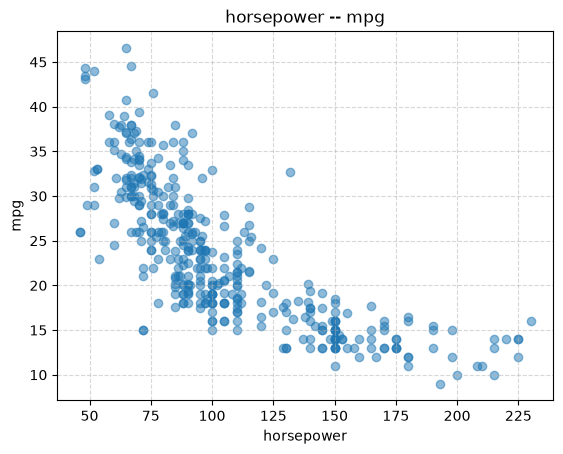

In [39]:
x = datos['horsepower']
y = datos['mpg']

plt.scatter(x,y, alpha=0.5)
plt.title('horsepower -- mpg')
plt.xlabel('horsepower')
plt.ylabel('mpg')
plt.grid(True, alpha=0.5, linestyle='--')

- La relacion es descendente y presenta una curva.
- El rendimiento no disminuye al mismo ritmo en todo el rango.
- Una recta puede representar la tendencia general, pero falla en algunas zonas de la curva.

***PASO 6***<BR>_DATOS DE ENTRENAMIENTO Y PRUEBA_

In [40]:
x = datos[['horsepower']]
y = datos['mpg']

xtrain, xtest, ytrain, ytest = train_test_split(x,y, test_size=0.2, random_state=42)
print(xtrain.shape, xtest.shape)
print(ytrain.shape, ytest.shape)

(313, 1) (79, 1)
(313,) (79,)


con dos corchetes sklearn nos manda una matriz en r2, mientras que con un solo corchete, nos da un vector con pandas en r1. Lo exigen para que cumplan los requisitos internos de sklearn para recibir uno o mas variables en x y solo uno para que pueda ver los resultados en el enrtenamiento.

- X usa doble corchete porque debe ser una tabla de dos dimensiones.
- y usa uno porque es una serie de una dimension.
- X_train y X_test tienen una columna; y_train e y_test son vectores.

***PASO 7***<BR>_ENTRENAR EL MODELO BASE: REGRESION LINEAL_

In [41]:
modelo = LinearRegression()
modelo.fit(xtrain, ytrain)

ypred = modelo.predict(xtest)

mse = mean_squared_error(ytest, ypred)
rmse = np.sqrt(mse)
r2 = r2_score(ytest, ypred)

print('rmse:',rmse)
print('r2:',r2)

rmse: 4.706722545876634
r2: 0.5659681822256183


el error cuadrado medio es 4.7 por lo tanto puede fluctuar entre +/- 5 mpg aprox. Son 57% de la variacion del modelo

- El RMSE indica un error tipico aproximado de 4.71 millas por galon.
- El modelo explica aproximadamente 56.6% de la variacion de mpg.

***PASO 8***<BR>_ENTRENAR UN MODELO POLINOMIAL DE GRADO 2_

In [ ]:
modelo_grado2 = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2),
    LinearRegression()
)
modelo_grado2.fit(xtrain, ytrain)
pred_grado2 = modelo_grado2.predict(xtest)

rmse_grado2 = np.sqrt(mean_squared_error(ytest, pred_grado2))
r2_grado2 = r2_score(ytest, pred_grado2)

print(f"RMSE grado 2: {rmse_grado2:.3f}")
print(f"R2 grado 2: {r2_grado2:.3f}")

RMSE grado 2: 4.291
R2 grado 2: 0.639


In [71]:
transformador = modelo_grado2.named_steps["polynomialfeatures"]
X_tres = xtrain.iloc[:3]
columnas = transformador.fit_transform(
    modelo_grado2.named_steps["standardscaler"].transform(X_tres)
)
nombres = transformador.get_feature_names_out(["horsepower_escalado"])
print("\nColumnas polinomiales para los tres primeros autos de entrenamiento:")
print(pd.DataFrame(columnas, columns=nombres, index=X_tres.index))


Columnas polinomiales para los tres primeros autos de entrenamiento:
       1  horsepower_escalado  horsepower_escalado^2
260  1.0             0.141429               0.020002
184  1.0            -0.329499               0.108569
174  1.0            -0.198685               0.039476


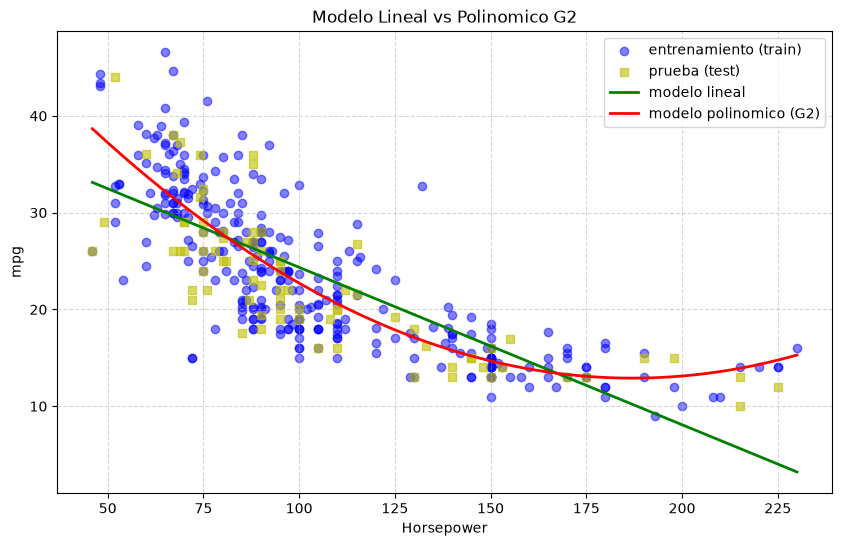

In [ ]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(xtrain, ytrain)

x_range = np.linspace(xtrain.min(), xtrain.max(), 200).reshape(-1, 1)
x_range_df = pd.DataFrame(x_range, columns=xtrain.columns)

y_lineal_smooth = modelo_lineal.predict(x_range_df)
y_poly_smooth = modelo_grado2.predict(x_range_df)

plt.figure(figsize=(10, 6))

plt.scatter(xtrain, ytrain, color='b', alpha=0.5, label='entrenamiento (train)')
plt.scatter(xtest, ytest, color='y', alpha=0.6, label='prueba (test)', marker='s')

plt.plot(x_range_df, y_lineal_smooth, color='g', linewidth=2, label='modelo lineal')
plt.plot(x_range_df, y_poly_smooth, color='r', linewidth=2, label='modelo polinomico (G2)')

plt.xlabel('Horsepower')
plt.ylabel('mpg')
plt.title('Modelo Lineal vs Polinomico G2')
plt.legend()
plt.grid(True, alpha=0.5, linestyle='--')
plt.show()

1. *base* o sesgo incial, *horsepower* efecto lineal, *horsepower^2* curvatura.<br>
elevamos al cuadrado para evitar problemas por la diferencia de escalas.<br>
sel equivoca mas por debajo de la recta y por encima, la curva lo crrige acercandose mas a los puntos que forma el df
- PolynomialFeatures crea una columna constante, x y x al cuadrado.
- Escalar ayuda a que los valores tengan una escala manejable antes de crear potencias.
- La curva puede representar mejor los cambios de rendimiento que una recta.

***PASO 9***<BR>_ELEGIR EL GRADO CON VALIDACION CRUZADA_

In [45]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
resultados = []

In [46]:
for grado in range(1, 11):
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grado), LinearRegression())
    scores = cross_val_score(pipe, x, y, scoring="neg_root_mean_squared_error", cv=kf)
    resultados.append((grado, -scores.mean()))

df_res = pd.DataFrame(resultados, columns=["Grado", "RMSE"])
print(df_res)

   Grado      RMSE
0      1  4.894760
1      2  4.349300
2      3  4.352889
3      4  4.364644
4      5  4.326803
5      6  4.317422
6      7  4.309927
7      8  4.333277
8      9  4.356307
9     10  4.425222


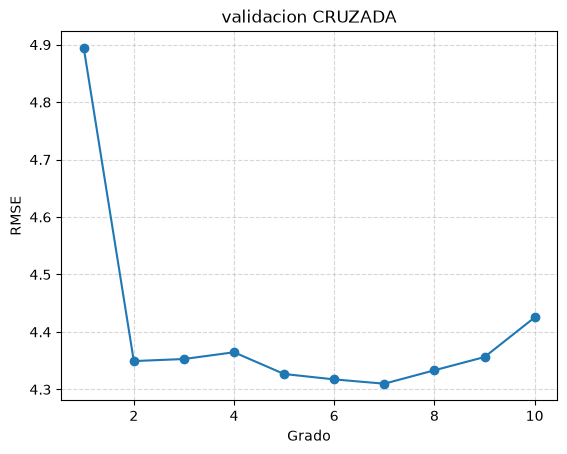

In [47]:
plt.plot(df_res["Grado"], df_res["RMSE"], marker='o')
plt.title('validacion CRUZADA')
plt.xlabel("Grado")
plt.ylabel("RMSE")
plt.grid(True, alpha=0.5, linestyle='--')

el error RMSE disminuye al aumentar el grado, pero llega un momento que se vuelve inestable. No el grado con menor error no siempre es el mejor. Aplicando el principio de PARSIMONIA, los grados 2 y 3 son estables, No se usa el conjunto de puerba porque justamente esta reservado para para evaluar el modelo.

***PASO 10***<BR>_EVALUAR EL MODELO FINAL_ 

In [48]:
grado_optimo = 2
modelo_lineal = LinearRegression()
modelo_lineal.fit(xtrain, ytrain)
y_pred_lin = modelo_lineal.predict(xtest)

pipe_final = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grado_optimo), LinearRegression())
pipe_final.fit(xtrain, ytrain)
y_pred_poly = pipe_final.predict(xtest)

tabla = pd.DataFrame({
    "Modelo": ["Lineal", f"Polinómico (Grado {grado_optimo})"],
    "RMSE": [np.sqrt(mean_squared_error(ytest, y_pred_lin)), np.sqrt(mean_squared_error(ytest, y_pred_poly))],
    "R2": [r2_score(ytest, y_pred_lin), r2_score(ytest, y_pred_poly)]
})
print(tabla)

                 Modelo      RMSE        R2
0                Lineal  4.706723  0.565968
1  Polinómico (Grado 2)  4.291499  0.639170


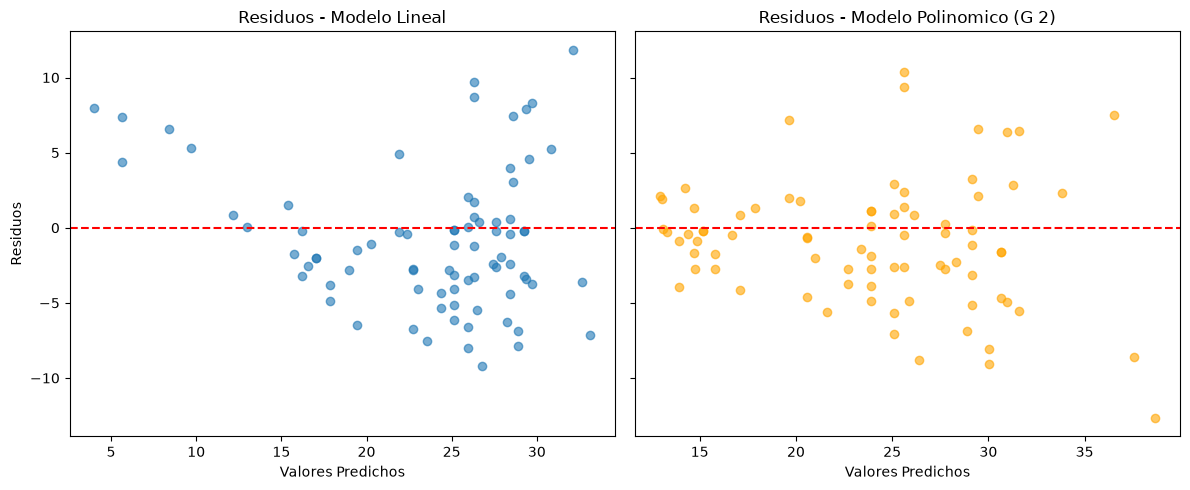

In [52]:
residuos_lin = ytest - y_pred_lin
residuos_poly = ytest - y_pred_poly

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(y_pred_lin, residuos_lin, alpha=0.6)
axes[0].axhline(0, color='r', linestyle='--')
axes[0].set_title("Residuos - Modelo Lineal")
axes[0].set_xlabel("Valores Predichos")
axes[0].set_ylabel("Residuos")

axes[1].scatter(y_pred_poly, residuos_poly, alpha=0.6, color='orange')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title(f"Residuos - Modelo Polinomico (G {grado_optimo})")
axes[1].set_xlabel("Valores Predichos")

plt.tight_layout()

In [53]:
transformador_final = PolynomialFeatures(degree=grado_optimo, include_bias=False)
X_train_poly = transformador_final.fit_transform(xtrain)
modelo_ecuacion = LinearRegression()
modelo_ecuacion.fit(X_train_poly, ytrain)

coeficientes = modelo_ecuacion.coef_
intercepto = modelo_ecuacion.intercept_

terminos = [f"({intercepto:.4f})"]
for i, coef in enumerate(coeficientes, start=1):
    terminos.append(f"({coef:.6f})*x^{i}")
ecuacion = "mpg = " + " + ".join(terminos)

print("\nEcuacion en unidades originales:")
print(ecuacion)


Ecuacion en unidades originales:
mpg = (58.2129) + (-0.484458)*x^1 + (0.001295)*x^2


mejora segun el rmse menor y mayor R2. Muestran una forma de U o arco. Si. En el modelo polinómico los residuos se distribuyen de forma aleatoria y simetrica alrededor de cero, sin ningún patrón sistemático visible

- Un patron curvo en los residuos lineales indica que la recta no captura toda la relacion.
- Si los residuos finales se dispersan mas aleatoriamente alrededor de cero, el polinomio mejora el ajuste.
- El signo de los coeficientes indica como contribuyen los terminos de cada potencia a la curva.

***PASO 11***<BR>_predecir y reconocer limites_ 

In [56]:
potencias_consulta = pd.DataFrame({"horsepower": [60, 100, 150, 200]})
predicciones = pipe_final.predict(potencias_consulta)

tabla_predicciones = pd.DataFrame({
    "horsepower": potencias_consulta["horsepower"],
    "mpg_predicho": predicciones
})
print(tabla_predicciones.to_string(index=False))

if grado_optimo == 2:
    beta1 = coeficientes[0]
    beta2 = coeficientes[1]
    if beta2 != 0:
        vertice = -beta1 / (2 * beta2)
        print(f"Vertice de la parabola: {vertice:.2f} hp")
        print(f"Rango de potencia observado: {datos['horsepower'].min():.2f} a {datos['horsepower'].max():.2f} hp")
    else:
        print("No se puede calcular el vertice porque el coeficiente cuadratico es cero.")
else:
    potencias_amplias = np.linspace(0, 300, 200)
    X_amplio = pd.DataFrame({"horsepower": potencias_amplias})
    plt.figure()
    plt.plot(potencias_amplias, pipe_final.predict(X_amplio))
    plt.title("Modelo final en un rango amplio")
    plt.xlabel("Potencia (hp)")
    plt.ylabel("Rendimiento (millas por galon)")
    plt.grid()
    plt.show()

 horsepower  mpg_predicho
         60     33.807091
        100     22.716134
        150     14.679499
        200     13.117379
Vertice de la parabola: 187.06 hp
Rango de potencia observado: 46.00 a 230.00 hp


- Las predicciones son mas confiables dentro del rango de potencias observado.
- Fuera de ese rango, la curva puede crecer o bajar de forma poco realista.
- La extrapolacion es predecir fuera de los datos observados y puede producir errores grandes.

***PASO 12***<BR>_CONCLUSIONES_

La relacion entre horsepower y mpg es descendente y no completamente recta. El modelo lineal obtuvo RMSE=4.707 y R2=0.566; el modelo polinomial de grado 2 obtuvo RMSE=4.291 y R2=0.639. Se eligio ese grado usando validacion cruzada y prefiriendo un modelo sencillo con error cercano al minimo. La regresion polinomial sigue siendo lineal porque estima coeficientes mediante una combinacion lineal de las columnas transformadas. Las predicciones deben interpretarse con cautela, especialmente fuera del rango de potencia observado.

In [7]:
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_excel('./lab.xlsx')
dependientes = df["NRODEPENDIENTES"].dropna()
muestra_30 = dependientes.sample(n=30,random_state=42)

print(muestra_30)

mu_0 = 1.65
alpha = 0.05

resultado_30 = stats.ttest_1samp(
    muestra_30,
    popmean=mu_0,
    alternative="two-sided"
)

print("Media muestral: ", muestra_30.mean())
print("Media hipotética: ",mu_0)
print("Esatdístico t: ",resultado_30.statistic)
print("Valor p: ",resultado_30.pvalue)


if resultado_30.pvalue < alpha:
    print("Decisión: Rechazar H0")
else:
    print("Decisión: No rechazar H0")

4148     4
7841     4
18898    4
4194     3
8409     0
24725    1
2508     2
20879    1
17758    4
2905     3
8358     2
3316     2
7484     0
19364    2
12518    0
23303    2
17137    1
8241     1
8979     2
9683     0
12917    1
15912    4
9109     1
12044    2
10279    2
25145    0
23432    3
25419    4
8641     4
11955    1
Name: NRODEPENDIENTES, dtype: int64
Media muestral:  2.0
Media hipotética:  1.65
Esatdístico t:  1.3555441711725964
Valor p:  0.18570805017274147
Decisión: No rechazar H0


In [8]:
df = pd.read_excel('./lab.xlsx')
dependientes = df["NRODEPENDIENTES"].dropna()
muestra_30 = dependientes.sample(n=100,random_state=42)

print(muestra_30)

mu_0 = 1.65
alpha = 0.05

resultado_30 = stats.ttest_1samp(
    muestra_30,
    popmean=mu_0,
    alternative="two-sided"
)

print("Media muestral: ", muestra_30.mean())
print("Media hipotética: ",mu_0)
print("Esatdístico t: ",resultado_30.statistic)
print("Valor p: ",resultado_30.pvalue)


if resultado_30.pvalue < alpha:
    print("Decisión: Rechazar H0")
else:
    print("Decisión: No rechazar H0")

4148     4
7841     4
18898    4
4194     3
8409     0
        ..
3578     0
1246     3
14655    0
17525    3
7547     2
Name: NRODEPENDIENTES, Length: 100, dtype: int64
Media muestral:  1.7
Media hipotética:  1.65
Esatdístico t:  0.33928789997547454
Valor p:  0.7351115261296519
Decisión: No rechazar H0


In [9]:
df = pd.read_excel('./lab.xlsx')
dependientes = df["NRODEPENDIENTES"].dropna()
muestra_30 = dependientes.sample(n=500,random_state=42)

print(muestra_30)

mu_0 = 1.65
alpha = 0.05

resultado_30 = stats.ttest_1samp(
    muestra_30,
    popmean=mu_0,
    alternative="two-sided"
)

print("Media muestral: ", muestra_30.mean())
print("Media hipotética: ",mu_0)
print("Esatdístico t: ",resultado_30.statistic)
print("Valor p: ",resultado_30.pvalue)


if resultado_30.pvalue < alpha:
    print("Decisión: Rechazar H0")
else:
    print("Decisión: No rechazar H0")

4148     4
7841     4
18898    4
4194     3
8409     0
        ..
11582    1
3050     3
24080    4
21853    0
25193    2
Name: NRODEPENDIENTES, Length: 500, dtype: int64
Media muestral:  1.676
Media hipotética:  1.65
Esatdístico t:  0.38405043355860086
Valor p:  0.7011046618587122
Decisión: No rechazar H0


In [ ]:
dependientes = df["NRODEPENDIENTES"].dropna()


mu_0=1.65
alpha = 0.05


resultados = []


for semilla in range(10):
  
    muestra = dependientes.sample(
        n=30,
        random_state=semilla
    )


    prueba = stats.ttest_1samp(
        muestra,
        popmean=mu_0,
        alternative="two-sided"
    )


    decision = (
        "Decisión: Rechazar H0"
        if prueba.pvalue < alpha
        else "Decisión: No rechazar H0"
    )
    #media_muestra = np.mean(muestra)
    resultados.append({
        "Semilla: ": semilla,
        "Media Muestral: ": media_muestra.mean(),
        "Estadístico t: ": prueba.statistic,
        "Valor p: ": prueba.pvalue,
        "Decisón: ":decision
    })


tabla_resultados = pd.DataFrame(resultados)
tabla_resultados

,Semilla:,Media Muestral:,Estadístico t:,Valor p:,Decisón:
0,0,2.0,0.432291,0.668728,Decisión: No rechazar H0
1,1,2.0,-1.127169,0.268911,Decisión: No rechazar H0
2,2,2.0,2.621687,0.013791,Decisión: Rechazar H0
3,3,2.0,-0.174779,0.862468,Decisión: No rechazar H0
4,4,2.0,0.841980,0.406689,Decisión: No rechazar H0
5,5,2.0,0.889654,0.380973,Decisión: No rechazar H0
6,6,2.0,0.611632,0.545547,Decisión: No rechazar H0
7,7,2.0,0.413172,0.682520,Decisión: No rechazar H0
8,8,2.0,0.298367,0.767551,Decisión: No rechazar H0
9,9,2.0,1.113213,0.274759,Decisión: No rechazar H0
